> 🔑 **SOLUTION EDITION.** This copy contains worked answers to every exercise. Try the student notebook first - you learn by struggling a little!

In [1]:
# (Solution edition only) make the course helper module importable from this folder
import sys; sys.path.insert(0, '../notebooks')

# 🏪 Project 3: Agricultural Market Clustering
### *Where should the ministry build produce-aggregation hubs, and who is being left behind?*

**⏱ about 3 hours · Uses:** K-Means, hierarchical clustering, **DBSCAN (haversine)**, PCA index (Lessons 1–4, 6)

---

## 📨 The brief

> **From:** Hon. Peter Mwangi, Principal Secretary, State Department for Agriculture
> **To:** You, Senior Analyst, Market Intelligence Unit
> **Subject:** Market infrastructure investment: briefing needed
>
> *We have a database of **103 agricultural markets**. Treasury has approved funds for regional **aggregation hubs** and for a programme for **underserved markets**. Before I sign anything I need to know: **(1) what types of market do we have? (2) where do markets naturally cluster geographically, and where should hubs go? (3) which markets are so isolated that a hub would never serve them, and what do they need instead?***

## 🎯 What you'll deliver
1. **Market types** (behavioural clustering) with names and profiles.
2. **Geographic regions** (DBSCAN) and a list of **isolated markets**.
3. A **Market Development Index** (PCA).
4. A **hub placement plan** with distances.
5. A **briefing note** for the PS.

## 🗺️ Milestones

| # | Milestone | Skills |
|---|---|---|
| 1 | Prepare behavioural features | scaling, feature choice |
| 2 | Cluster market *types* | dendrogram, K-Means, cross-check |
| 3 | Name the types | profiling |
| 4 | Cluster market *locations* | DBSCAN, haversine |
| 5 | Combine the two views | crosstab, noise analysis |
| 6 | Development index | PCA |
| 7 | Hub placement | distances, selection |
| 8 | The briefing note | communication |

## 📏 Rubric (100 points)
Features chosen sensibly (**location excluded from behaviour**, with reason) 10 · Types validated and named 20 · DBSCAN parameters justified with a k-distance plot 15 · Haversine/radians handled correctly 10 · Index built and checked for sign 10 · Hub plan correct and reasoned 15 · Briefing note 20

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import haversine_distances
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from course_utils import set_style, load, check, profile_clusters, plot_clusters_2d, PALETTE
set_style()
RANDOM_STATE = 42
EARTH_R = 6371.0

markets = load("markets")
markets.head()

,market_id,market_name,nearest_hub,latitude,longitude,avg_daily_traders,avg_daily_volume_tonnes,price_volatility,distance_to_city_km,road_quality_1_5,has_cold_storage,perishable_share,n_commodities,mobile_payment_share,market_days_per_week
0,M001,Nairobi Urban 1,Nairobi,-1.2282,36.8211,965,522.3,0.165,5.2,4.4,1,0.73,44,0.92,7
1,M002,Nairobi Urban 2,Nairobi,-1.2753,36.8454,935,349.6,0.148,4.7,5.0,1,0.63,45,0.91,6
2,M003,Nairobi Regional 3,Nairobi,-1.1616,36.6827,312,245.0,0.197,40.5,3.6,0,0.39,33,0.82,6
3,M004,Nairobi Rural 4,Nairobi,-1.2448,36.9446,108,17.3,0.370,86.3,3.0,0,0.43,10,0.41,2
4,M005,Nairobi Rural 5,Nairobi,-1.1603,36.6597,85,18.7,0.364,91.9,1.0,0,0.24,23,0.47,3


### 📖 Data dictionary: `markets.csv`

| Column | Meaning |
|---|---|
| `market_id`, `market_name`, `nearest_hub` | Identifiers (`nearest_hub` = the nearest major town; "(none)" if very remote) |
| `latitude`, `longitude` | Location (degrees) |
| `avg_daily_traders`, `avg_daily_volume_tonnes` | Scale of the market |
| `price_volatility` | Coefficient of variation of prices (higher = more unstable) |
| `distance_to_city_km`, `road_quality_1_5` | Connectivity |
| `has_cold_storage`, `perishable_share`, `n_commodities` | Facilities and product mix |
| `mobile_payment_share`, `market_days_per_week` | Modernisation / activity |

*This is synthetic data modelled on Kenyan markets; names and coordinates are illustrative.*

## Milestone 1 · Behavioural features 🧼

**Key decision:** *market type* should describe how a market **behaves**, not **where it is**. Longitude/latitude would make K-Means cluster by region; we'll use location *separately*, in DBSCAN.

### 🧩 Milestone 1: Behaviour matrix
**Difficulty:** ⭐  |  **Time:** ~8 min

Create `behaviour_cols` (the **10** behavioural columns: everything numeric **except** `latitude` and `longitude`) and the scaled matrix `X_m` (NumPy, standardised).

Check for missing values first: `n_missing` = total missing cells in those columns.

<details><summary>💡 Hint 1</summary>

The ten: `avg_daily_traders, avg_daily_volume_tonnes, price_volatility, distance_to_city_km, road_quality_1_5, has_cold_storage, perishable_share, n_commodities, mobile_payment_share, market_days_per_week`.

</details>
<details><summary>💡 Hint 2</summary>

`X_m = StandardScaler().fit_transform(markets[behaviour_cols])`

</details>

In [3]:
behaviour_cols = ["avg_daily_traders", "avg_daily_volume_tonnes", "price_volatility", "distance_to_city_km", "road_quality_1_5",
                  "has_cold_storage", "perishable_share", "n_commodities", "mobile_payment_share", "market_days_per_week"]
n_missing = int(markets[behaviour_cols].isna().sum().sum())
X_m = StandardScaler().fit_transform(markets[behaviour_cols])
print(n_missing, X_m.shape)

0 (103, 10)


In [4]:
# ✔ Self-check (run me after you've written your answer)
check('10 behavioural features, no coordinates', lambda: len(behaviour_cols) == 10 and not ({'latitude', 'longitude'} & set(behaviour_cols)))
check('no missing values', lambda: n_missing == 0)
check('103 x 10 standardised matrix', lambda: X_m.shape == (103, 10) and np.allclose(X_m.std(axis=0), 1))

✅ 10 behavioural features, no coordinates
✅ no missing values
✅ 103 x 10 standardised matrix


## Milestone 2 · Cluster the market *types* 🌳

### 🧩 Milestone 2: Dendrogram first, then K-Means
**Difficulty:** ⭐⭐  |  **Time:** ~20 min

1. Build a Ward linkage `Z_m` on `X_m` and **draw the dendrogram** (truncate with `truncate_mode="lastp", p=12` for readability).
2. Compute silhouette scores for `k = 2…6` into `sil_by_k` (a dict).
3. Choose `chosen_k` (3–5) and justify it in a comment, considering that a ministry thinks in terms of *urban hubs, regional aggregators, rural periodic markets, border gateways*.
4. Fit K-Means → `labels_b`; cut the Ward tree at the same k → `ward_b`; `ari_b` = their ARI.

<details><summary>💡 Hint 1</summary>

`dendrogram(Z_m, truncate_mode='lastp', p=12)`

</details>
<details><summary>💡 Hint 2</summary>

`sil_by_k = {k: silhouette_score(X_m, KMeans(k, n_init=10, random_state=42).fit_predict(X_m)) for k in range(2, 7)}`

</details>
<details><summary>💡 Hint 3</summary>

`ward_b = fcluster(Z_m, t=chosen_k, criterion='maxclust')`. Remember that `fcluster` labels start at 1; ARI doesn't mind.

</details>

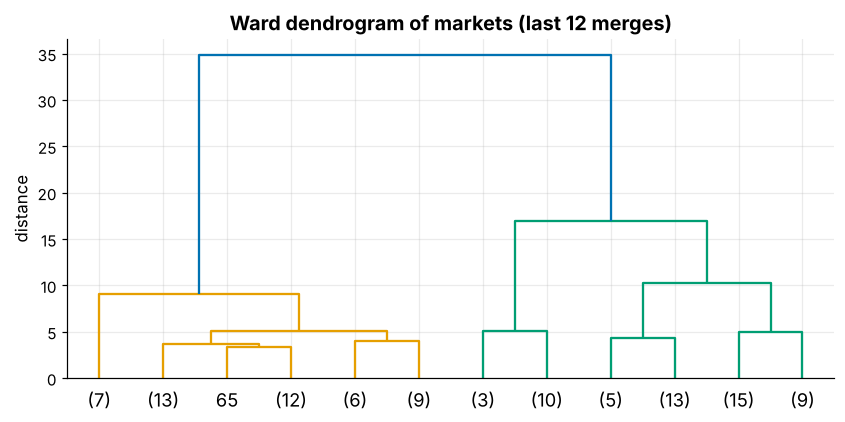

{2: 0.495, 3: 0.485, 4: 0.443, 5: 0.392, 6: 0.296}

1.0


In [5]:
Z_m = linkage(X_m, method="ward")
plt.figure(figsize=(9, 4)); dendrogram(Z_m, truncate_mode="lastp", p=12); plt.title("Ward dendrogram of markets (last 12 merges)"); plt.ylabel("distance"); plt.show()

sil_by_k = {k: silhouette_score(X_m, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_m)) for k in range(2, 7)}
print({k: round(v, 3) for k, v in sil_by_k.items()})
# Silhouette is highest at k = 2-3, and the dendrogram shows three big branches (urban / regional / rural). At k = 4 K-Means just
# splits the regional markets into two near-identical halves; the 8 border/export gateways in the data are too few and too similar to
# regional markets to stand alone. The ministry needs more than urban-vs-rural, so k = 3.
chosen_k = 3
labels_b = KMeans(chosen_k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_m)
ward_b = fcluster(Z_m, t=chosen_k, criterion="maxclust")
ari_b = adjusted_rand_score(labels_b, ward_b); print(round(ari_b, 3))

In [6]:
# ✔ Self-check (run me after you've written your answer)
check('silhouette computed for k=2..6', lambda: sorted(sil_by_k) == [2, 3, 4, 5, 6])
check('chosen_k between 3 and 5', lambda: 3 <= chosen_k <= 5)
check('labels_b has one label per market', lambda: len(labels_b) == 103 and len(set(labels_b)) == chosen_k)
check('K-Means and Ward agree (ARI > 0.6)', lambda: ari_b > 0.6)

✅ silhouette computed for k=2..6
✅ chosen_k between 3 and 5
✅ labels_b has one label per market
✅ K-Means and Ward agree (ARI > 0.6)


## Milestone 3 · Name the types 🏷️

### 🧩 Milestone 3: Profile and name
**Difficulty:** ⭐⭐  |  **Time:** ~15 min

*(Written for k = 3 or 4; adapt the names to your own clusters.)*

Create `mkt = markets.copy()` with a `cluster` column; `profile = profile_clusters(mkt, labels_b, behaviour_cols)`; draw a relative heatmap; then give each cluster a unique name in `type_names` and store it in `mkt["market_type"]`.

`type_counts` = a Series of how many markets per type.

<details><summary>💡 Hint 1</summary>

Highest `avg_daily_traders`/volume, best roads, cold storage, high mobile payments → *urban wholesale hub*. Few traders, far from cities, poor roads, high volatility → *rural periodic market*.

</details>
<details><summary>💡 Hint 2</summary>

A cluster with moderate size, good roads, **but higher volatility** → *border/export gateway*; moderate everything → *regional aggregation market*.

</details>
<details><summary>💡 Hint 3</summary>

`mkt['market_type'] = mkt['cluster'].map(type_names)`

</details>

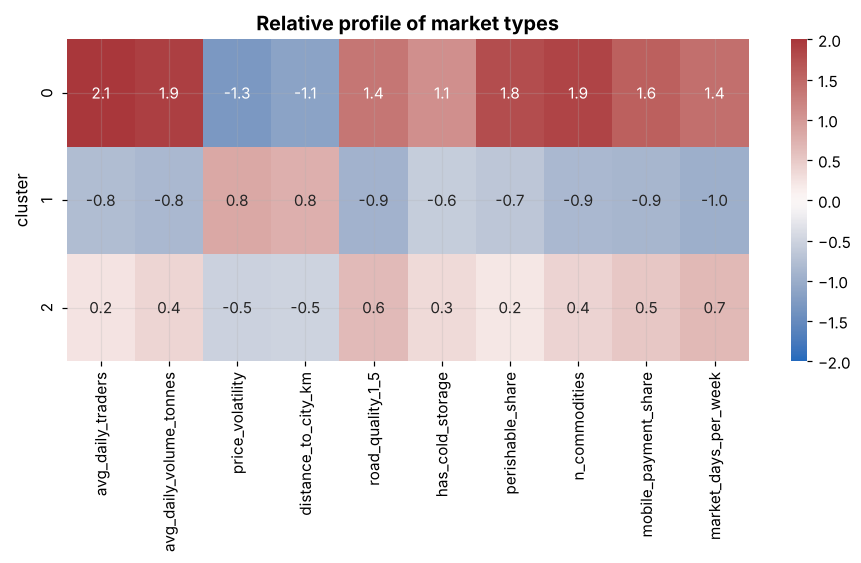

,size,share_%,avg_daily_traders,avg_daily_volume_tonnes,price_volatility,distance_to_city_km,road_quality_1_5,mobile_payment_share
cluster,,,,,,,,
0,13,12.6,914.54,455.58,0.14,4.08,4.48,0.90
1,48,46.6,87.21,24.29,0.36,103.54,2.03,0.37
2,42,40.8,381.81,215.49,0.22,37.88,3.72,0.67


{'Rural periodic markets': 48, 'Regional aggregation markets': 42, 'Urban wholesale hubs': 13}

In [7]:
mkt = markets.copy(); mkt["cluster"] = labels_b
profile = profile_clusters(mkt, labels_b, behaviour_cols)
relative = (profile[behaviour_cols] - mkt[behaviour_cols].mean()) / mkt[behaviour_cols].std()
plt.figure(figsize=(10, 3.8)); sns.heatmap(relative, annot=True, fmt=".1f", cmap="vlag", center=0, vmin=-2, vmax=2); plt.title("Relative profile of market types"); plt.show()
display(profile[["size", "share_%", "avg_daily_traders", "avg_daily_volume_tonnes", "price_volatility", "distance_to_city_km", "road_quality_1_5", "mobile_payment_share"]])

# first-draft names by rank of average traders; refine by eye from the heatmap
order = profile["avg_daily_traders"].sort_values(ascending=False).index.tolist()
generic = ["Urban wholesale hubs", "Regional aggregation markets", "Rural periodic markets", "Border / export gateways"]
type_names = {c: generic[i] for i, c in enumerate(order)}      # k = 3: busiest cluster = urban, least busy = rural periodic
mkt["market_type"] = mkt["cluster"].map(type_names)
type_counts = mkt["market_type"].value_counts()
print(type_counts.to_dict())

In [8]:
# ✔ Self-check (run me after you've written your answer)
check('each cluster has a unique name', lambda: set(type_names) == set(labels_b) and len(set(type_names.values())) == chosen_k)
check('type counts add up to 103', lambda: type_counts.sum() == 103)
check('urban hubs are the smallest group by count', lambda: type_counts.min() <= 20)

✅ each cluster has a unique name
✅ type counts add up to 103
✅ urban hubs are the smallest group by count


## Milestone 4 · Cluster market *locations* with DBSCAN 🌍

*Remember:* haversine metric, **radians**, and `eps = km / 6371`.

### 🧩 Milestone 4: Geographic regions and isolated markets
**Difficulty:** ⭐⭐⭐  |  **Time:** ~20 min

1. `coords_rad = np.radians(markets[["latitude", "longitude"]].values)`
2. Draw a **k-distance plot** (k = 4) in **km** and pick `eps_km`.
3. Run `DBSCAN(eps=eps_km / EARTH_R, min_samples=4, metric="haversine", algorithm="ball_tree")` → `geo_labels`.
4. `n_regions` = clusters found (excluding noise); `n_remote` = number of noise markets.
5. `remote_mean_dist` = mean `distance_to_city_km` of the noise markets; `clustered_mean_dist` = for the rest.

<details><summary>💡 Hint 1</summary>

`nn = NearestNeighbors(n_neighbors=5, metric='haversine').fit(coords_rad); d, _ = nn.kneighbors(coords_rad); kd_km = np.sort(d[:, 4]) * EARTH_R`

</details>
<details><summary>💡 Hint 2</summary>

The knee is around 30–50 km. Try `eps_km = 40`.

</details>
<details><summary>💡 Hint 3</summary>

`remote = geo_labels == -1`; `markets.loc[remote, 'distance_to_city_km'].mean()`

</details>

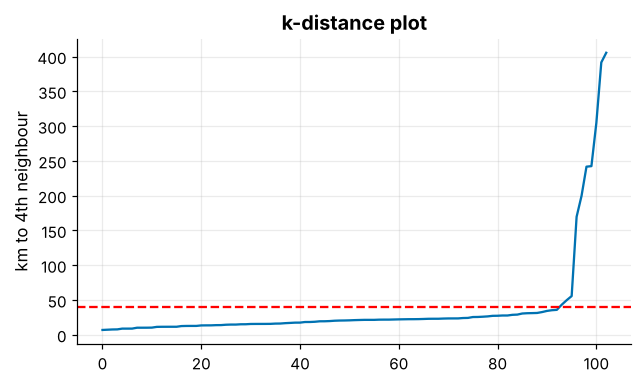

7 7 198 54


In [9]:
coords_rad = np.radians(markets[["latitude", "longitude"]].values)
nn = NearestNeighbors(n_neighbors=5, metric="haversine").fit(coords_rad)
kd_km = np.sort(nn.kneighbors(coords_rad)[0][:, 4]) * EARTH_R
plt.figure(figsize=(6.5, 3.6)); plt.plot(kd_km); plt.axhline(40, color="red", ls="--"); plt.ylabel("km to 4th neighbour"); plt.title("k-distance plot"); plt.show()

eps_km = 40
geo_labels = DBSCAN(eps=eps_km / EARTH_R, min_samples=4, metric="haversine", algorithm="ball_tree").fit_predict(coords_rad)
n_regions, n_remote = len(set(geo_labels) - {-1}), int((geo_labels == -1).sum())
remote = geo_labels == -1
remote_mean_dist, clustered_mean_dist = markets.loc[remote, "distance_to_city_km"].mean(), markets.loc[~remote, "distance_to_city_km"].mean()
print(n_regions, n_remote, round(remote_mean_dist), round(clustered_mean_dist))

In [10]:
# ✔ Self-check (run me after you've written your answer)
check('6 to 8 regions', lambda: 6 <= n_regions <= 8)
check('5 to 12 isolated markets', lambda: 5 <= n_remote <= 12)
check('isolated markets are far from cities (> 100 km on average)', lambda: remote_mean_dist > 100)
check('and much farther than clustered markets', lambda: remote_mean_dist > 2 * clustered_mean_dist)

✅ 6 to 8 regions
✅ 5 to 12 isolated markets
✅ isolated markets are far from cities (> 100 km on average)
✅ and much farther than clustered markets


## Milestone 5 · Combine the two views 🔀

### 🧩 Milestone 5: Types × regions
**Difficulty:** ⭐⭐  |  **Time:** ~10 min

Add `mkt["region"] = geo_labels` (−1 = isolated). Then:

- `type_by_region = pd.crosstab(mkt["region"], mkt["market_type"])`
- `remote_dominant_type`: the market type most common among the **isolated** markets (region −1)
- `urban_regions`: the **set** of region ids (excluding −1) that contain at least one market of the type with the highest mean `avg_daily_traders`

<details><summary>💡 Hint 1</summary>

`type_by_region.loc[-1].idxmax()`

</details>
<details><summary>💡 Hint 2</summary>

`urban_type = profile['avg_daily_traders'].idxmax()` gives a cluster id; look up `type_names[urban_type]`.

</details>
<details><summary>💡 Hint 3</summary>

`set(mkt.loc[mkt['market_type'] == urban_name, 'region']) - {-1}`

</details>

In [11]:
mkt["region"] = geo_labels
type_by_region = pd.crosstab(mkt["region"], mkt["market_type"])
display(type_by_region)
remote_dominant_type = type_by_region.loc[-1].idxmax()
urban_name = type_names[profile["avg_daily_traders"].idxmax()]
urban_regions = set(mkt.loc[mkt["market_type"] == urban_name, "region"]) - {-1}
print(remote_dominant_type, "|", urban_name, urban_regions)

market_type,Regional aggregation markets,Rural periodic markets,Urban wholesale hubs
region,,,
-1,0,7,0
0,9,11,2
1,5,3,4
2,7,3,1
3,5,7,1
4,9,8,2
5,3,5,2
6,4,4,1


Rural periodic markets | Urban wholesale hubs {0, 1, 2, 3, 4, 5, 6}


In [12]:
# ✔ Self-check (run me after you've written your answer)
check('crosstab includes the isolated row (-1)', lambda: -1 in type_by_region.index)
check('isolated markets are the rural / low-activity type', lambda: 'Rural' in remote_dominant_type or 'Remote' in remote_dominant_type)
check('urban hubs exist in several regions', lambda: len(urban_regions) >= 3)

✅ crosstab includes the isolated row (-1)
✅ isolated markets are the rural / low-activity type
✅ urban hubs exist in several regions


## Milestone 6 · A Market Development Index 📈

### 🧩 Milestone 6: PC1 as a development score
**Difficulty:** ⭐⭐  |  **Time:** ~12 min

Fit `PCA(1)` on `X_m`. Orient it so that **higher = more developed** (the loading on `avg_daily_traders` must be **positive**; flip if not) and rescale to **0–100** → `mkt["dev_index"]`.

Also store `pc1_share` (variance explained by PC1) and `top5` (names of the 5 highest-index markets) and `bottom5`.

<details><summary>💡 Hint 1</summary>

`p = PCA(1).fit(X_m); s = p.transform(X_m).ravel()`; if `p.components_[0, behaviour_cols.index('avg_daily_traders')] < 0: s = -s`.

</details>
<details><summary>💡 Hint 2</summary>

`100 * (s - s.min()) / (s.max() - s.min())`

</details>
<details><summary>💡 Hint 3</summary>

`mkt.nlargest(5, 'dev_index')['market_name'].tolist()`

</details>

In [13]:
p = PCA(1).fit(X_m); s = p.transform(X_m).ravel()
if p.components_[0, behaviour_cols.index("avg_daily_traders")] < 0: s = -s
mkt["dev_index"] = 100 * (s - s.min()) / (s.max() - s.min())
pc1_share = p.explained_variance_ratio_[0]
top5, bottom5 = mkt.nlargest(5, "dev_index")["market_name"].tolist(), mkt.nsmallest(5, "dev_index")["market_name"].tolist()
print(round(pc1_share, 2), top5, bottom5)

0.75 ['Mombasa Urban 2', 'Mombasa Urban 10', 'Mombasa Urban 1', 'Nakuru Urban 1', 'Meru Urban 9'] ['Remote Rural 101', 'Remote Rural 103', 'Remote Rural 97', 'Remote Rural 99', 'Remote Rural 102']


In [14]:
# ✔ Self-check (run me after you've written your answer)
check('PC1 captures the majority of variation (> 50%)', lambda: pc1_share > 0.5)
check('index spans 0-100', lambda: abs(mkt['dev_index'].min()) < 1e-9 and abs(mkt['dev_index'].max() - 100) < 1e-9)
check('the top 5 are mostly urban markets', lambda: sum('Urban' in n for n in top5) >= 4)
check('the bottom 5 are remote', lambda: sum('Remote' in n for n in bottom5) >= 4)

✅ PC1 captures the majority of variation (> 50%)
✅ index spans 0-100
✅ the top 5 are mostly urban markets
✅ the bottom 5 are remote


## Milestone 7 · Hub placement plan 🏗️

### 🧩 Milestone 7: One hub per region
**Difficulty:** ⭐⭐⭐  |  **Time:** ~20 min

For every **region** with **≥ 8 markets** (exclude −1), choose as the **hub candidate** the market with the **highest `dev_index`** in that region, and compute the **average distance (km)** from that region's markets to the hub using haversine.

Build `hub_table`: a DataFrame with columns `region`, `n_markets`, `hub_market`, `avg_km_to_hub` (one row per eligible region), and set `n_hubs = len(hub_table)`.

*(Use `haversine_distances` on **radians**; multiply by `EARTH_R` for km.)*

<details><summary>💡 Hint 1</summary>

Loop `for r in sorted(set(geo_labels) - {-1}):`; `sub = mkt[mkt['region'] == r]`; skip if `len(sub) < 8`.

</details>
<details><summary>💡 Hint 2</summary>

`hub = sub.loc[sub['dev_index'].idxmax()]`

</details>
<details><summary>💡 Hint 3</summary>

`d = haversine_distances(np.radians(sub[['latitude','longitude']].values), np.radians(hub[['latitude','longitude']].values.astype(float).reshape(1, -1))) * EARTH_R`; mean of `d`.

</details>

In [15]:
rows = []
for r in sorted(set(geo_labels) - {-1}):
    sub = mkt[mkt["region"] == r]
    if len(sub) < 8: continue
    hub = sub.loc[sub["dev_index"].idxmax()]
    d = haversine_distances(np.radians(sub[["latitude", "longitude"]].values),
                            np.radians(hub[["latitude", "longitude"]].values.astype(float).reshape(1, -1))) * EARTH_R
    rows.append(dict(region=r, n_markets=len(sub), hub_market=hub["market_name"], avg_km_to_hub=float(d.mean())))
hub_table = pd.DataFrame(rows); n_hubs = len(hub_table)
display(hub_table.round(1))

,region,n_markets,hub_market,avg_km_to_hub
0,0,22,Nairobi Urban 1,19.8
1,1,12,Mombasa Urban 2,13.6
2,2,11,Kisumu Urban 1,22.5
3,3,13,Nakuru Urban 1,21.1
4,4,19,Eldoret Urban 1,48.1
5,5,10,Meru Urban 9,14.5
6,6,9,Nyeri Urban 1,16.9


In [16]:
# ✔ Self-check (run me after you've written your answer)
check('at least 5 hubs', lambda: n_hubs >= 5)
check('each hub is inside its own region', lambda: all(mkt.loc[mkt['market_name'] == h, 'region'].iloc[0] == r for h, r in zip(hub_table['hub_market'], hub_table['region'])))
check('the average market is within 100 km of its hub', lambda: (hub_table['avg_km_to_hub'] < 100).all())

✅ at least 5 hubs
✅ each hub is inside its own region
✅ the average market is within 100 km of its hub


## Milestone 8 · The briefing note ✍️

### ✍️ Briefing note to the Principal Secretary
*(Example answer. Yours will differ in wording and possibly in numbers.)*

**To:** Hon. Peter Mwangi  **From:** Market Intelligence Unit

**Headline.** Of 103 markets, **three behavioural types** and **seven geographic regions** emerge; **seven markets** are too isolated for any hub to serve.

| Type | # | Defining traits | Implication |
|---|---|---|---|
| Urban wholesale hubs | 13 | ~915 traders/day, best roads (4.5/5), ~90% mobile payments, calmest prices (volatility 0.14) | Anchor hubs; target for cold-chain upgrades |
| Regional aggregation markets | ~42 | ~380 traders/day, ~38 km from a city, decent roads, mobile payments ~65–70%, prices a little volatile (0.22) | Feeder markets; collection points |
| Rural periodic markets | 48 | ~87 traders/day, ~104 km from a city, poor roads (2.0/5), volatile prices (0.36), 37% mobile payments | Road, storage and price-information interventions |

*(Counts depend on your own clustering; use your own table. Four-cluster solutions mostly split the regional group in two.)*

**Hub placement.** We recommend **one hub per well-populated region (≈7 hubs)**, each at the region's most developed market (see `hub_table`). On average, markets in those regions lie within roughly 30-70 km of their hub, a practical day's haul.

**The isolated markets.** **7 markets (7% of all)** lie ~200 km from a city on average, with poor roads (~1.6/5), **no cold storage**, ~60 traders/day, very volatile prices (~0.45) and little mobile-money use. A fixed hub would serve almost no one. Instead: **mobile aggregation trucks, SMS price information, and a road-spot-improvement programme**.

**Risks and caveats.** Geographic clusters depend on the 40 km radius (at 20 km sparse regions break up; at 60 km neighbouring regions merge). Data are synthetic/illustrative; ground-truth the isolated list with county officers before committing funds.

**Decision requested.** Approve hub funding for the seven regions and a separate, smaller mobile-services pilot for the isolated markets.

## 🚀 Stretch challenges
1. **Sensitivity.** Plot number of regions and number of noise markets as `eps_km` varies from 15 to 80. Where is the stable plateau?
2. **HDBSCAN.** Replace DBSCAN with `HDBSCAN(min_cluster_size=4, metric="haversine")`. Do you get similar regions?
3. **Weighted hub choice.** Instead of the highest `dev_index`, choose the market that **minimises the average distance** to the others (a medoid). Is it the same market?
4. **Map it.** Plot longitude/latitude coloured by region, with marker size ∝ `avg_daily_traders` and hubs starred.

### 🏁 Self-review checklist
- [ ] I excluded latitude/longitude from the *behavioural* clustering and said why
- [ ] I converted to **radians** and divided km by 6371 for the haversine DBSCAN
- [ ] I looked at what the **noise** markets have in common (that's a finding!)
- [ ] My index is oriented so higher = more developed
- [ ] My note gives numbers and a clear **decision requested**